# Phase 5: Model Development, Evaluation, and Selection
## Customer Churn Prediction System

This notebook benchmarks multiple classification algorithms using 5-Fold Stratified Cross-Validation, optimizes hyperparameters for the best model architecture, calibrates decision thresholds for business impact, and conducts final evaluation on the untouched test set.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from churn_prediction.config import (
    PROCESSED_DATA_DIR,
    RANDOM_STATE,
    MODELS_DIR,
    ALL_FEATURE_COLS,
)
from churn_prediction.model_training import (
    cross_validate_models,
    build_full_pipeline,
    tune_best_model,
)
from churn_prediction.evaluation import (
    evaluate_predictions,
    sweep_thresholds,
    plot_confusion_matrix,
    plot_roc_and_pr_curves,
    plot_threshold_tradeoffs,
)
from churn_prediction.model_inference import ChurnPredictor, load_model_bundle

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.dpi"] = 120
%matplotlib inline

### 1. Ingestion of Cleaned Training & Test Datasets

In [2]:
train_df = pd.read_csv(PROCESSED_DATA_DIR / "train.csv")
test_df = pd.read_csv(PROCESSED_DATA_DIR / "test.csv")

X_train = train_df[ALL_FEATURE_COLS]
y_train = train_df["Churn Value"]
X_test = test_df[ALL_FEATURE_COLS]
y_test = test_df["Churn Value"]

print(f"Train set: {X_train.shape}, Churn rate: {y_train.mean():.4f}")
print(f"Test set:  {X_test.shape}, Churn rate: {y_test.mean():.4f}")

Train set: (5634, 19), Churn rate: 0.2654
Test set:  (1409, 19), Churn rate: 0.2654


### 2. Candidate Model Benchmarking (5-Fold Stratified CV)
We evaluate Dummy Classifier, Logistic Regression, Decision Tree, Random Forest, HistGradientBoosting, and XGBoost.

In [3]:
cv_results = cross_validate_models(X_train, y_train, cv_folds=5, random_state=RANDOM_STATE)
display(cv_results)

,Model,ROC-AUC (Mean),ROC-AUC (Std),PR-AUC (Mean),PR-AUC (Std),Recall (Mean),Recall (Std),Precision (Mean),Precision (Std),F1-Score (Mean),F1-Score (Std),Accuracy (Mean)
3,Random Forest,0.862387,0.009101,0.680496,0.017855,0.804682,0.030550,0.544747,0.019819,0.649428,0.020225,0.769439
5,XGBoost,0.862361,0.010020,0.687806,0.018648,0.812709,0.025383,0.532507,0.013808,0.643329,0.016329,0.760919
1,Logistic Regression,0.858801,0.012464,0.678896,0.020778,0.810033,0.034199,0.529436,0.019827,0.640062,0.021128,0.758257
4,HistGradientBoosting,0.849406,0.006133,0.657621,0.010746,0.733779,0.020355,0.563144,0.010763,0.637009,0.008736,0.778135
2,Decision Tree,0.845333,0.008275,0.625404,0.016257,0.812709,0.022084,0.514186,0.014012,0.629483,0.006971,0.746009
0,Dummy (Majority Class),0.500000,0.000000,0.265353,0.000094,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.734647


### 3. Hyperparameter Tuning (HistGradientBoosting)
We tune the HistGradientBoostingClassifier using GridSearchCV.

In [4]:
best_pipeline, best_params = tune_best_model(
    X_train, y_train, model_type="HistGradientBoosting", cv_folds=5, random_state=RANDOM_STATE
)
print("Optimal Hyperparameters:")
for param, val in best_params.items():
    print(f"  {param}: {val}")

Fitting 5 folds for each of 16 candidates, totalling 80 fits


Optimal Hyperparameters:
  classifier__class_weight: None
  classifier__learning_rate: 0.03
  classifier__max_iter: 100
  classifier__max_leaf_nodes: 15
  classifier__min_samples_leaf: 50


### 4. Threshold Optimization for High Recall Retention
We sweep decision thresholds from 0.05 to 0.95 on cross-validation probabilities.

Optimal F1 Threshold: 0.30 (F1=0.6507, Recall=0.7806)


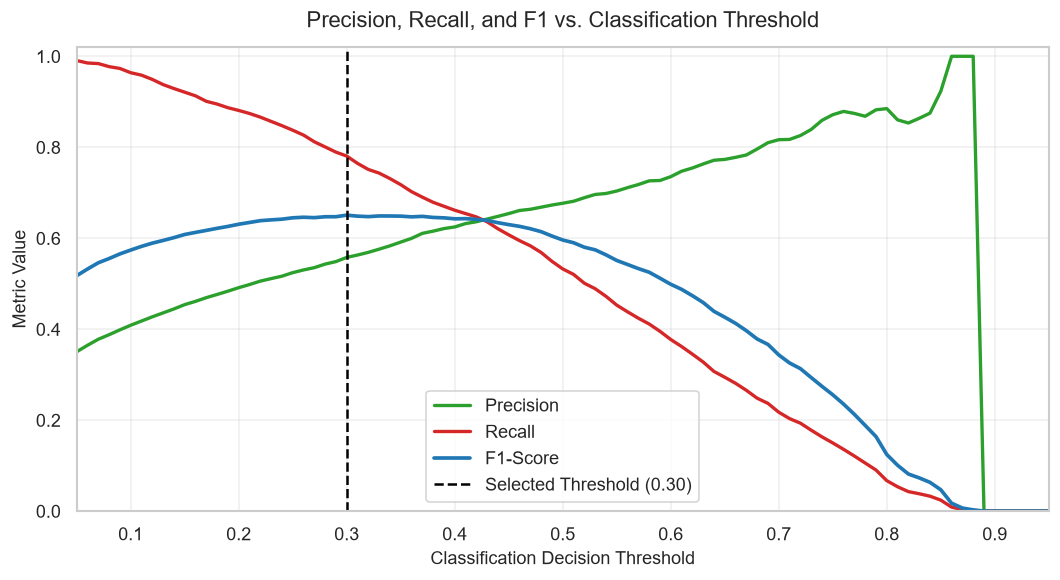

In [5]:
from sklearn.model_selection import cross_val_predict

cv_probs = cross_val_predict(best_pipeline, X_train, y_train, cv=5, method="predict_proba")[:, 1]
sweep_df = sweep_thresholds(y_train.values, cv_probs)

best_f1_idx = sweep_df["f1"].idxmax()
opt_thresh = float(sweep_df.loc[best_f1_idx, "threshold"])
print(f"Optimal F1 Threshold: {opt_thresh:.2f} (F1={sweep_df.loc[best_f1_idx, 'f1']:.4f}, Recall={sweep_df.loc[best_f1_idx, 'recall']:.4f})")

fig = plot_threshold_tradeoffs(sweep_df, optimal_threshold=opt_thresh)
plt.show()

### 5. Final Evaluation on Untouched Test Set
We evaluate on the untouched test set using both the standard 0.50 threshold and the calibrated 0.30 threshold.

In [6]:
best_pipeline.fit(X_train, y_train)
test_probs = best_pipeline.predict_proba(X_test)[:, 1]

metrics_std = evaluate_predictions(y_test.values, test_probs, threshold=0.50)
metrics_cal = evaluate_predictions(y_test.values, test_probs, threshold=opt_thresh)

eval_comparison = pd.DataFrame([
    {"Threshold": "0.50 (Standard)", "ROC-AUC": metrics_std["roc_auc"], "PR-AUC": metrics_std["pr_auc"], "Recall": metrics_std["recall"], "Precision": metrics_std["precision"], "F1-Score": metrics_std["f1"], "Accuracy": metrics_std["accuracy"], "Captured Churners": f"{metrics_std['tp']}/374"},
    {"Threshold": f"{opt_thresh:.2f} (Calibrated)", "ROC-AUC": metrics_cal["roc_auc"], "PR-AUC": metrics_cal["pr_auc"], "Recall": metrics_cal["recall"], "Precision": metrics_cal["precision"], "F1-Score": metrics_cal["f1"], "Accuracy": metrics_cal["accuracy"], "Captured Churners": f"{metrics_cal['tp']}/374"},
])
display(eval_comparison)

,Threshold,ROC-AUC,PR-AUC,Recall,Precision,F1-Score,Accuracy,Captured Churners
0,0.50 (Standard),0.857025,0.674017,0.526738,0.672355,0.590705,0.806246,197/374
1,0.30 (Calibrated),0.857025,0.674017,0.770053,0.542373,0.636464,0.766501,288/374


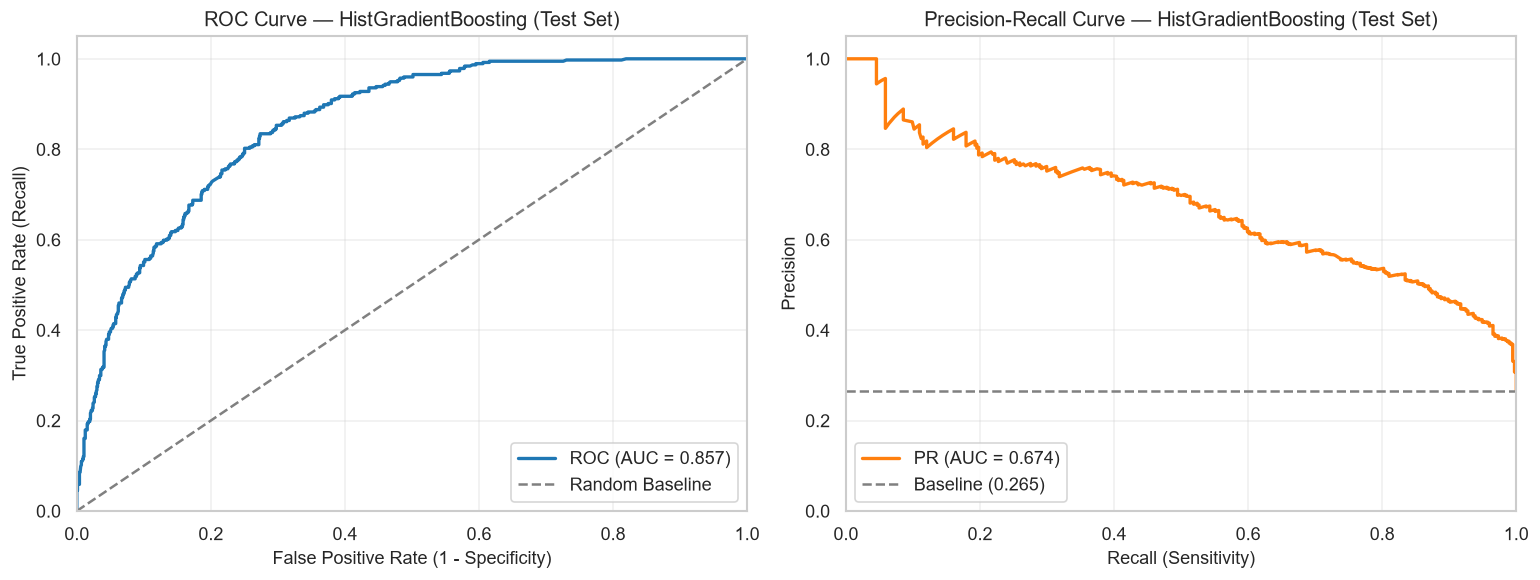

In [7]:
# Plot test set ROC & PR curves
fig = plot_roc_and_pr_curves(y_test.values, test_probs, model_name="HistGradientBoosting (Test Set)")
plt.show()

### 6. Production Model Inference Testing
We load the serialized production model bundle from `models/churn_pipeline_bundle.joblib` and score sample customer accounts.

In [8]:
predictor = ChurnPredictor(MODELS_DIR / "churn_pipeline_bundle.joblib")
sample_batch = X_test.head(5).copy()
scored_results = predictor.score_records(sample_batch)

display(scored_results[["Tenure Months", "Contract", "Monthly Charges", "churn_probability", "churn_prediction", "churn_label", "risk_tier"]])

,Tenure Months,Contract,Monthly Charges,churn_probability,churn_prediction,churn_label,risk_tier
0,72,Two year,114.05,0.0448,0,No,Low Risk
1,8,Month-to-month,100.15,0.7382,1,Yes,High Risk
2,41,One year,78.35,0.0869,0,No,Low Risk
3,18,Month-to-month,78.20,0.4165,1,Yes,Medium Risk
4,72,Two year,82.65,0.0418,0,No,Low Risk
